In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル開発環境を検出しました。リポジトリルート:", repo_root)


💻 ローカル開発環境を検出しました。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 8.4 スタック領域の移動 (`osbook_day08b`)
### *Switching Kernel Stack to Dedicated .bss Memory & System V AMD64 ABI Invariants*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/8/8.4_Switching_Kernel_Stack.ipynb)

---

## 🎯 本節の目的と学習到達目標

前節（8.3節）では、ブートローダ（`MikanLoaderPkg/Main.c`）から渡された画面構成情報 `FrameBufferConfig` とメモリマップ `MemoryMap` を値コピーし、過渡的な UEFI メモリからカーネルの保護下へ退避させる手法を確立しました。

しかし、カーネルには依然として **「時限爆弾」とも言える致命的な脆弱性** が残されています。
それは、**「CPU のスタックポインタ（`RSP`）が依然として UEFI ファームウェアの用意した一時的なスタック領域を指している」** という事実です。

本節では、以下の重要項目をステップ・バイ・ステップで理論導出・実装・視覚化します：

1. **UEFI スタック領域の危険性と OS 自前スタックの必然性**:
   - `ExitBootServices()` 後、ファームウェアのスタック領域は OS にとって「再利用可能な空きメモリ（`EfiBootServicesData` または `EfiConventionalMemory`）」となり、将来のメモリアロケータによって上書きされるリスク。
   - UEFI スタックのサイズ限界（通常 32KiB〜64KiB 程度）とスタックオーバーフローの脅威。
2. **`.bss` 領域への 1MiB 独自スタックの確保**:
   - `alignas(16) uint8_t kernel_main_stack[1024 * 1024];` の構造と、実行ファイルサイズを肥大化させない `.bss` セクションの特性。
3. **x86-64 下位伸長スタック（Full Descending Stack）の数理**:
   - スタックトップアドレス $\text{RSP}_{\text{init}} = \text{kernel\_main\_stack} + 1024 \times 1024$ の厳密な導出。
   - `PUSH` / `POP` / `CALL` / `RET` 命令におけるポインタ減算・加算の仕組みと配列境界の安全性。
4. **System V AMD64 ABI と 16 バイトスタックアライメント規約**:
   - 関数呼び出し直前（`call` 命令直前）における $\text{RSP} \equiv 0 \pmod{16}$、および関数エントリ時における $\text{RSP} \equiv 8 \pmod{16}$ の不変条件（Invariants）。
   - SSE / AVX 命令（`movaps` 等）がアライメント違反で引き起こす一般保護例外（`#GP: General Protection Fault`）のメカニズム。
5. **アセンブリ（`KernelMain`）と C++（`KernelMainNewStack`）の連携**:
   - `asmfunc.asm` によるスタック切り替え、引数レジスタ（`RDI`, `RSI`）の透過的フォワード、および `.fin: hlt` ループによる関数復帰時の暴走防止。


---

## 8.4.1 UEFI スタックの危険性と OS 自前スタックの必然性

### 1. CPU は起動直後どこでスタックを使っているのか？

PC が電源投入され、UEFI BIOS が起動してブートローダ `BOOTX64.EFI`、そしてカーネル `kernel.elf` を呼び出す際、CPU のスタックポインタレジスタ **`RSP` (Stack Pointer)** はどこを指しているのでしょうか？

UEFI 仕様書 (*Unified Extensible Firmware Interface Specification*) において、ファームウェアは UEFI アプリケーション（ブートローダ）を実行するために、物理メモリ内に一時的なスタック領域を割り当てます。
この領域のメモリ種別は通常 **`EfiBootServicesData`** または **`EfiLoaderData`** に分類されています。

カーネルのエントリポイント `KernelMain` にジャンプした直後、CPU の `RSP` は依然としてこの **UEFI ファームウェアが用意したスタック** を指し続けています。

### 2. ExitBootServices() 呼び出し後の致命的な時限爆弾

第8章の冒頭から繰り返し強調している通り、ブートローダが `ExitBootServices()` を呼び出した瞬間、UEFI ブートサービスは完全に終了し、ファームウェアはメモリの制御を放棄します。

前節（8.3節）で確認した通り、OS のメモリ管理機構（8.7節で実装する `BitmapMemoryManager`）は、メモリマップを走査して以下の領域をすべて **「カーネルが自由に使ってよい空きメモリ（Available RAM）」** として管理下に組み入れます：
- `EfiConventionalMemory`（元々の空き物理RAM）
- `EfiBootServicesCode`（ブートローダやUEFIサービスの実行コード領域）
- `EfiBootServicesData`（ブートローダやUEFIサービスが使っていたデータ領域 ← **ここにUEFIスタックがある！**）

```
[UEFI スタックの破滅的タイムライン]

1. ブート時:          UEFI ファームウェアが 0x70000000 付近にスタック (64KiB) を確保
2. KernelMain突入:   カーネルが UEFI スタック上で動作開始 (RSP ≈ 0x7000FFF0)
3. 8.7節 メモリ管理:  BitmapMemoryManager が 0x70000000 を「空きメモリ」として登録
4. 将来のメモリ確保:  ドライバやウィンドウバッファが 0x70000000 を要求して割り当て
5. メモリ書き込み:    割り当てられたバッファにデータを書き込んだ瞬間...
                     💥 カーネルの現在実行中スタックフレーム（戻りアドレスやローカル変数）が破壊！
                     💥 即座に CPU が未定義命令を実行してクラッシュ（トリプルフォールト / 再起動）
```

### 3. UEFI スタックのサイズ制限とオーバーフローのリスク

危険性はメモリの再利用だけにとどまりません。
UEFI ファームウェアがブートローダ向けに用意するスタックサイズは、仕様上厳密に保証されているわけではなく、マザーボードやファームウェア実装依存（典型的には **32 KiB 〜 64 KiB 程度**）です。

しかし、本格的な OS カーネルでは以下の処理がスタックを消費します：
- 深い関数呼び出し階層（ファイルシステムの走査、ELF バイナリの解析、ページテーブル構築）
- 割り込み発生時のハードウェアコンテキスト退避（`InterruptFrame`）
- デバッグ出力用の書式整形バッファ（`char buf[1024]`）

もし 64 KiB を超えてスタックを消費すると、**スタックオーバーフロー（Stack Overflow）** が発生し、スタックの下に隣接する未割り当てメモリや重要なファームウェア構造体を破壊してしまいます。

> [!CAUTION]
> **結論**: OS カーネルが自身の制御下にある永続的なメモリ領域に、十分なサイズ（1 MiB 以上）の専用スタックを確保し、`ExitBootServices()` 後できる限り早い段階で `RSP` を切り替えることは、**OS の生存にとって絶対不可欠な要件**です。


---

## 8.4.2 x86-64 下位伸長スタック（Full Descending Stack）の数理

### 1. スタックの4つの分類と x86-64 の仕様

計算機アーキテクチャにおいて、スタックのメモリアクセス方式には以下の4つの分類が存在します：

| 分類 | スタックポインタが指す位置 | スタックの伸長方向 | 代表的なアーキテクチャ |
|:---:|:---:|:---:|:---:|
| **Full Ascending (FA)** | 最後に積まれたデータ | 高位アドレス側（増加） | 一部の ARM (任意設定可能) |
| **Empty Ascending (EA)** | 次に積む空きスロット | 高位アドレス側（増加） | 一部の DSP |
| **Empty Descending (ED)** | 次に積む空きスロット | 低位アドレス側（減少） | - |
| **Full Descending (FD)** | **最後に積まれたデータ** | **低位アドレス側（減少）** | **x86 / x86-64, ARM (標準)** |

**x86-64 アーキテクチャは「Full Descending（満杯下位伸長型）」をハードウェアレベルで採用しています。**

### 2. x86-64 スタック操作命令の数学的定義

スタックポインタ `RSP` とスタック操作命令の動作は、以下の数式で厳密に定義されます：

#### ① `PUSH` 命令 (例: `push rax`)
まず `RSP` が減算され、その後で新しい値が書き込まれます。
$$\text{RSP} \leftarrow \text{RSP} - 8$$
$$\text{Memory}[\text{RSP}] \leftarrow \text{RAX}$$

#### ② `POP` 命令 (例: `pop rax`)
まず `RSP` が指すアドレスから値が読み出され、その後で `RSP` が加算されます。
$$\text{RAX} \leftarrow \text{Memory}[\text{RSP}]$$
$$\text{RSP} \leftarrow \text{RSP} + 8$$

#### ③ `CALL` 命令 (例: `call KernelMainNewStack`)
次命令のメモリアドレス（戻り先アドレス $\text{RIP}_{\text{next}}$）をスタックにプッシュし、ジャンプします。
$$\text{RSP} \leftarrow \text{RSP} - 8$$
$$\text{Memory}[\text{RSP}] \leftarrow \text{RIP}_{\text{next}}$$
$$\text{RIP} \leftarrow \text{KernelMainNewStack}$$

#### ④ `RET` 命令
スタックから戻り先アドレスをポップして `RIP` に復帰します。
$$\text{RIP} \leftarrow \text{Memory}[\text{RSP}]$$
$$\text{RSP} \leftarrow \text{RSP} + 8$$

---

### 3. なぜ初期 RSP は配列の先頭ではなく「末尾アドレス」なのか？

MikanOS では、カーネルの `.bss` セクション内に以下の 1 MiB の配列を宣言します（`kernel/main.cpp`）：

```cpp
alignas(16) uint8_t kernel_main_stack[1024 * 1024];
```

この配列のメモリ配置は以下のようになります：
- 配列の先頭アドレス（最下位アドレス）: $\text{Base} = \text{reinterpret\_cast}<\text{uintptr\_t}>(\text{kernel\_main\_stack})$
- 配列のサイズ: $\text{Size} = 1024 \times 1024 = 1,048,576\text{ バイト } (= 0x100000)$
- 配列の有効インデックス範囲: $[\text{Base}, \text{Base} + \text{Size} - 1]$

もし誤って $\text{RSP} = \text{Base}$（配列の先頭アドレス）をセットしてしまうとどうなるでしょうか？
最初の `call` 命令が実行された瞬間：
$$\text{RSP} = \text{Base} - 8$$
となり、**配列の有効範囲を下方に飛び出し（Out-of-Bounds Underflow）、隣接する別の変数を破壊してしまいます！**

x86-64 は下位に向かって伸びる（Full Descending）ため、**スタックの初期位置（スタックトップ）は配列の末尾アドレス** に設定しなければなりません：

$$\text{RSP}_{\text{init}} = \text{Base} + \text{Size} = \text{kernel\_main\_stack} + 1024 \times 1024$$

この状態で最初の `call` 命令が実行されると：
$$\text{RSP} \leftarrow (\text{Base} + 1048576) - 8 = \text{Base} + 1048568$$
$$\text{Memory}[\text{Base} + 1048568] \leftarrow \text{Return Address}$$

書き込み先アドレスは $\text{Base} + 1048568$ であり、配列の最後の 8 バイトスロット $[\text{Base} + 1048568, \text{Base} + 1048576)$ に**1バイトの狂いもなく完全に収まります！**


---

## 8.4.3 System V AMD64 ABI と 16 バイトスタックアライメント規約

### 1. System V AMD64 ABI の基本原則

Linux や macOS、そして MikanOS をはじめとする多くの x86-64 OS は、呼出規約およびバイナリ仕様として **System V AMD64 ABI (*Application Binary Interface*)** を採用しています。

この仕様書（*System V Application Binary Interface AMD64 Architecture Processor Supplement*）の **Section 3.2.2 The Stack Frame** には、極めて重大な制約が記載されています：

> *"The end of the input argument area shall be aligned on a 16 (32, if __m256 is passed on stack) byte boundary. In other words, the value (%rsp + 8) is always a multiple of 16 (32) when control is transferred to the function entry point."*

これを数理的に整理すると、以下の厳密な不変条件（Invariants）が成立します：

```
[System V AMD64 ABI スタックアライメントの不変条件]

1. CALL 命令実行直前 (Pre-Call):
   RSP ≡ 0 (mod 16)   ; 16 バイト境界に整列していること！

2. 被呼出関数の先頭 (Function Entry):
   CALL 命令が 8 バイトのリターンアドレスをスタックにプッシュした直後であるため:
   RSP ≡ 8 (mod 16)   ; または (RSP + 8) ≡ 0 (mod 16)

3. プロローグ push rbp 実行直後 (Post-Prologue):
   8 バイトの旧 RBP がスタックにプッシュされるため:
   RSP ≡ 0 (mod 16)   ; 再び 16 バイト境界に整列！

4. ローカル変数領域確保 (Local Allocation):
   コンパイラはローカル変数を確保する際、必ず 16 の倍数（sub rsp, 16*N）で減算する:
   RSP ≡ 0 (mod 16)   ; 関数実行中、常に 16 バイト境界を維持！
```

### 2. なぜ 16 バイトアライメントを破ると CPU はクラッシュするのか？

単にメモリを 8 バイト単位で使うだけなら、8 バイト境界（アドレスの末尾3ビットが0）でも CPU は動くはずです。なぜ ABI はわざわざ 16 バイトアライメントを強制するのでしょうか？

その理由は、x86-64 CPU に搭載されている **SIMD (Single Instruction, Multiple Data) 拡張命令セット（SSE / AVX）** にあります。

現代のコンパイラ（GCC / Clang）は、最適化レベル `-O2` や `-O3` において、構造体のコピーやメモリのゼロクリア、ベクトル演算を行う際、SSE の 128 ビット（16 バイト）レジスタ `XMM0`〜`XMM15` を用いるコードを自動生成します。

ここで使われる最も高速な命令が **`movaps` (*Move Aligned Packed Single-Precision Floating-Point Values*)** です：

```nasm
movaps [rsp], xmm0   ; XMM0 (16バイト) を RSP が指すメモリアドレスへ一括転送
```

この命令には、Intel / AMD のハードウェア仕様により **「メモリアドレスが 16 バイト境界（下位 4 ビットが `0000_2`）に整列していなければならない」** という絶対制約があります。

もしスタックポインタのアライメントが崩れ、`RSP % 16 != 0` の状態で `movaps` が実行された瞬間、CPU のハードウェア MMU は **例外 13 番「#GP (General Protection Fault: 一般保護例外)」** を即座に発生させます！
OS 初期化段階では例外ハンドラ（IDT）が未設定、または十分なエラーリカバリができないため、システムは即死（Triple Fault によるリセット）します。

### 3. C++20 `alignas(16)` によるアライメントの保証

MikanOS では、スタック配列の宣言に C++ 標準の **アライメント指定子 `alignas(16)`** を付与しています：

```cpp
alignas(16) uint8_t kernel_main_stack[1024 * 1024];
```

これにより、リンカ（LLD）は `.bss` セクション内のこの配列を、必ず **16 の倍数アドレス（`Address & 0xF == 0`）** に配置します。
さらに、配列サイズ $1024 \times 1024 = 1,048,576 = 16 \times 65,536$ も 16 の倍数です。

したがって：
$$\text{RSP}_{\text{init}} = \text{Base} + 1,048,576$$
$$\text{RSP}_{\text{init}} \pmod{16} = (\text{Base} \pmod{16} + 1,048,576 \pmod{16}) \pmod{16} = (0 + 0) \pmod{16} = 0$$

初期スタックポインタ $\text{RSP}_{\text{init}}$ は、**数学的に完全に 16 バイト境界に整列することが保証されます！**


---

## 8.4.4 アセンブリ（`KernelMain`）による `RSP` 切り替えと引数レジスタフォワード

### 1. `kernel/asmfunc.asm` の実装

スタックポインタ `RSP` の書き換えは、C++ 言語の構文上では直接記述することができません（インラインアセンブラを使わない限り）。
そのため、MikanOS ではブートローダから直接呼び出されるエントリシンボル `KernelMain` を **アセンブリ言語（NASM）** で実装しています。

```nasm
extern kernel_main_stack
extern KernelMainNewStack

global KernelMain
KernelMain:
    mov rsp, kernel_main_stack + 1024 * 1024
    call KernelMainNewStack
.fin:
    hlt
    jmp .fin
```

### 2. 1行ごとの動作と ABI レジスタの不変性

この短いアセンブリコードには、計算機工学上の重要な設計が凝縮されています：

1. **`mov rsp, kernel_main_stack + 1024 * 1024`**:
   - スタックポインタ `RSP` を、UEFI スタックからカーネル独自 1MiB スタックの末尾アドレスへ瞬時に切り替えます。
   - この命令の直後、$\text{RSP} \equiv 0 \pmod{16}$（16バイト整列）です。
2. **引数レジスタ（`RDI`, `RSI`）の透過的フォワード**:
   - ブートローダ（`MikanLoaderPkg/Main.c`）は、System V AMD64 ABI に従って以下のレジスタに引数を格納して `KernelMain` を呼び出します：
     - **`RDI`**: 第1引数 `const FrameBufferConfig& frame_buffer_config` のメモリアドレス
     - **`RSI`**: 第2引数 `const MemoryMap& memory_map` のメモリアドレス
   - `mov rsp, ...` 命令は汎用レジスタ `RDI`, `RSI` の値を一切変更しません。
   - 続く `call KernelMainNewStack` を呼び出す際、`RDI` と `RSI` にはブートローダが渡したポインタがそのまま無傷で残っています！
   - これにより、`KernelMainNewStack` は何の手続きも挟むことなく、第1引数・第2引数をそのまま受け取ることができます。
3. **`call KernelMainNewStack`**:
   - 8 バイトの戻り先アドレス（直後の `.fin` のアドレス）を新しいスタックにプッシュします。
   - `KernelMainNewStack` 関数先頭に突入した瞬間、$\text{RSP} \equiv 8 \pmod{16}$ となり、System V ABI の規約を完全に充足します。
4. **`.fin: hlt; jmp .fin` による暴走ガード**:
   - `KernelMainNewStack` は OS のメインルーチンであり、本来はイベントループを回し続けるため決してリターンしてはいけません。
   - しかし、万が一バグや例外によって `KernelMainNewStack` が `ret` 命令でリターンしてしまった場合、CPU は直後の `.fin` ラベルに復帰します。
   - `hlt` 命令は次のハードウェア割り込みが来るまで CPU のクロック供給を停止して省電力待機に入ります。
   - `jmp .fin` によって無限ループを形成し、CPU が未定義メモリへ突き進んで暴走することを確実に防止します。


---

## 8.4.5 C++20 によるスタックメモリシミュレータの実装と対話型検証

ホスト環境（Linux / Colab）上で、カーネルスタックの確保・アライメント検証・スタック切り替えシーケンス・System V ABI 不変条件の数学的チェックを行う C++20 シミュレータ `src/ch08/kernel_stack_sim.cpp` を対話型コンパイルして実行します。


In [2]:
%%writefile /tmp/test_kernel_stack.cpp
#include <iostream>
#include <iomanip>
#include <cstdint>
#include <cstddef>
#include <vector>
#include <string>
#include <stdexcept>
#include <cassert>
#include <cstring>

namespace mikanos {

constexpr size_t kKernelStackSize = 1024 * 1024; // 1 MiB
constexpr size_t kRequiredAlignment = 16;         // 16-byte alignment required by System V ABI

alignas(16) uint8_t kernel_main_stack[kKernelStackSize];
alignas(16) uint8_t uefi_boot_stack[64 * 1024];

struct CpuState {
    uint64_t rip{0};
    uint64_t rsp{0};
    uint64_t rbp{0};
    uint64_t rdi{0};
    uint64_t rsi{0};
    uint64_t rax{0};
    bool halted{false};
};

class KernelStackSimulator {
public:
    KernelStackSimulator() {
        std::memset(kernel_main_stack, 0xCC, kKernelStackSize);
        std::memset(uefi_boot_stack, 0xAA, sizeof(uefi_boot_stack));
    }

    static uintptr_t get_kernel_stack_base() {
        return reinterpret_cast<uintptr_t>(kernel_main_stack);
    }

    static uintptr_t get_kernel_stack_top() {
        return get_kernel_stack_base() + kKernelStackSize;
    }

    static uintptr_t get_uefi_stack_top() {
        return reinterpret_cast<uintptr_t>(uefi_boot_stack) + sizeof(uefi_boot_stack);
    }

    static bool verify_stack_alignment() {
        uintptr_t base = get_kernel_stack_base();
        uintptr_t top = get_kernel_stack_top();
        return (base % kRequiredAlignment == 0) && (top % kRequiredAlignment == 0);
    }

    static bool is_valid_pre_call_rsp(uint64_t rsp) {
        return (rsp % kRequiredAlignment) == 0;
    }

    static bool is_valid_func_entry_rsp(uint64_t rsp) {
        return (rsp % kRequiredAlignment) == 8;
    }

    CpuState simulate_asm_stack_switch(uint64_t initial_rdi, uint64_t initial_rsi) {
        CpuState cpu;
        cpu.rsp = get_uefi_stack_top() - 8;
        cpu.rdi = initial_rdi;
        cpu.rsi = initial_rsi;
        cpu.rip = 0x100000;

        // Step 1: mov rsp, kernel_main_stack + 1024 * 1024
        cpu.rsp = static_cast<uint64_t>(get_kernel_stack_top());
        if (!is_valid_pre_call_rsp(cpu.rsp)) {
            throw std::runtime_error("System V ABI Violation: Pre-call RSP is not 16-byte aligned!");
        }

        // Step 2: call KernelMainNewStack (pushes 8-byte return address .fin)
        uint64_t return_address = cpu.rip + 12;
        cpu.rsp -= 8;
        *reinterpret_cast<uint64_t*>(cpu.rsp) = return_address;

        if (!is_valid_func_entry_rsp(cpu.rsp)) {
            throw std::runtime_error("System V ABI Violation: Function entry RSP is not 16n + 8 aligned!");
        }

        // Step 3: Verify RDI and RSI are intact
        if (cpu.rdi != initial_rdi || cpu.rsi != initial_rsi) {
            throw std::runtime_error("ABI Violation: Argument registers corrupted during stack switch!");
        }

        // Step 4: Prologue
        cpu.rsp -= 8;
        *reinterpret_cast<uint64_t*>(cpu.rsp) = cpu.rbp;
        cpu.rbp = cpu.rsp;

        if (!is_valid_pre_call_rsp(cpu.rsp)) {
            throw std::runtime_error("ABI Violation: Post-prologue RSP is not 16-byte aligned!");
        }

        // Epilogue
        cpu.rbp = *reinterpret_cast<uint64_t*>(cpu.rsp);
        cpu.rsp += 8;

        uint64_t popped_ret = *reinterpret_cast<uint64_t*>(cpu.rsp);
        cpu.rsp += 8;
        cpu.rip = popped_ret;

        if (cpu.rip == return_address) {
            cpu.halted = true;
        }

        return cpu;
    }
};

} // namespace mikanos

int main(int argc, char* argv[]) {
    using namespace mikanos;
    KernelStackSimulator sim;

    std::cout << "====================================================================
";
    std::cout << "  MikanOS Chapter 8.4: Kernel Stack Switching & System V ABI Report 
";
    std::cout << "====================================================================

";

    std::cout << "1. Kernel Stack Memory Placement (.bss Section):
";
    std::cout << "   - Base Address:    0x" << std::hex << KernelStackSimulator::get_kernel_stack_base() << std::dec << "
";
    std::cout << "   - Top Address:     0x" << std::hex << KernelStackSimulator::get_kernel_stack_top() << std::dec << "
";
    std::cout << "   - Size:            " << (kKernelStackSize / 1024) << " KiB (" << kKernelStackSize << " bytes)
";
    std::cout << "   - Alignment:       " << (KernelStackSimulator::get_kernel_stack_base() % 16 == 0 ? "16-byte aligned (OK)" : "MISALIGNED!") << "

";

    std::cout << "2. System V AMD64 ABI Stack Invariants:
";
    std::cout << "   - Pre-call RSP:    Must satisfy RSP % 16 == 0
";
    std::cout << "   - At Function Entry: (Pushed 8-byte return address) -> RSP % 16 == 8
";
    std::cout << "   - After 'push rbp': (Pushed 8-byte saved RBP)       -> RSP % 16 == 0
";
    std::cout << "   - SSE/AVX Safety:  Guarantees aligned movaps/movapd instructions never crash with #GP

";

    // Run tests
    assert(KernelStackSimulator::verify_stack_alignment());
    CpuState cpu = sim.simulate_asm_stack_switch(0xE0000000, 0x10000000);
    assert(cpu.halted);
    assert(cpu.rdi == 0xE0000000);
    assert(cpu.rsi == 0x10000000);
    std::cout << "[PASS] All Chapter 8.4 kernel stack switching tests passed successfully!
";
    return 0;
}


Writing /tmp/test_kernel_stack.cpp


In [3]:
# C++20 シミュレータのコンパイルと実行
!g++ -std=c++20 -O2 -Wall -Wextra /tmp/test_kernel_stack.cpp -o /tmp/test_kernel_stack
!/tmp/test_kernel_stack


/tmp/test_kernel_stack.cpp:120:18: warning: missing terminating " character
  120 |     std::cout << "====================================================================
      |                  ^
/tmp/test_kernel_stack.cpp:120:18: error: missing terminating " character
  120 |     std::cout << "====================================================================
      |                  ^~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
/tmp/test_kernel_stack.cpp:121:1: warning: missing terminating " character
  121 | ";
      | ^
/tmp/test_kernel_stack.cpp:121:1: error: missing terminating " character
  121 | ";
      | ^~
/tmp/test_kernel_stack.cpp:122:18: warning: missing terminating " character
  122 |     std::cout << "  MikanOS Chapter 8.4: Kernel Stack Switching & System V ABI Report
      |                  ^
/tmp/test_kernel_stack.cpp:122:18: error: missing terminating " character
  122 |     std::cout << "  MikanOS Chapter 8.4: Kernel Stack Switching & Sy

/tmp/test_kernel_stack.cpp: In function ‘int main(int, char**)’:
/tmp/test_kernel_stack.cpp:120:15: error: no match for ‘operator<<’ (operand types are ‘std::ostream’ {aka ‘std::basic_ostream<char>’} and ‘std::ostream’ {aka ‘std::basic_ostream<char>’})
  120 |     std::cout << "====================================================================
      |     ~~~~~~~~~ ^~
      |          |
      |          basic_ostream<[...]>
  121 | ";
  122 |     std::cout << "  MikanOS Chapter 8.4: Kernel Stack Switching & System V ABI Report
      |     ~~~~~~~~~  
      |          |
      |          basic_ostream<[...]>
/tmp/test_kernel_stack.cpp:120:15: note: candidate: ‘operator<<(int, int)’ (built-in)
  120 |     std::cout << "====================================================================
      |     ~~~~~~~~~~^~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  121 | ";
      | ~~             
  122 |     std::cout << "  MikanOS Chapter 8.4: Kernel Stack Switching &

/bin/bash: line 1: /tmp/test_kernel_stack: No such file or directory


---

## 8.4.6 Python によるスタック切り替え・アライメント・ポインタ演算の視覚化

Python (`common.os_sim`) を用いて、UEFI スタックからカーネル独自スタックへの移行、System V ABI 16 バイトアライメントの推移、および Full Descending Stack のポインタ演算をシミュレートし、高解像度図版を生成して可視化します。


In [4]:
import matplotlib.pyplot as plt
from PIL import Image
from common import (
    KernelStackSimulator,
    plot_fig8_10_kernel_stack_relocation_architecture,
    plot_fig8_11_system_v_abi_stack_alignment_rules,
    plot_fig8_12_stack_growth_and_pointer_arithmetics,
)

# 1. Python スタックシミュレータの実行
sim = KernelStackSimulator()
switch_res = sim.simulate_stack_switch(rdi_val=0xE000_0000, rsi_val=0x1000_0000)
cap_res = sim.simulate_stack_capacity(frame_size=64)
sse_ok = sim.simulate_sse_alignment_fault(misaligned=False)
sse_fault = sim.simulate_sse_alignment_fault(misaligned=True)

print("=" * 60)
print("  KernelStackSimulator シミュレーション結果レポート")
print("=" * 60)
print(f"• カーネルスタック底 (Base): 0x{switch_res['kernel_stack_base']:08X}")
print(f"• カーネルスタック頂 (Top):  0x{switch_res['kernel_stack_top']:08X}")
print(f"• Pre-Call RSP:             0x{switch_res['pre_call_rsp']:08X} (16バイト整列: {switch_res['pre_call_aligned']})")
print(f"• Function Entry RSP:       0x{switch_res['func_entry_rsp']:08X} (Offset % 16 == 8: {switch_res['func_entry_valid']})")
print(f"• Post-Prologue RSP:        0x{switch_res['post_prologue_rsp']:08X} (16バイト整列: {switch_res['post_prologue_aligned']})")
print(f"• RDI / RSI 引数保持:       RDI={switch_res['rdi_preserved']}, RSI={switch_res['rsi_preserved']}")
print(f"• スタック容量比較:          UEFI={cap_res['uefi_max_frames']} frames vs Kernel={cap_res['kernel_max_frames']} frames ({cap_res['depth_multiplier']}倍!)")
print(f"• SSE movaps (整列時):       {sse_ok['exception']}")
print(f"• SSE movaps (非整列時):     {sse_fault['exception']}")
print("=" * 60)

# 2. 高解像度図版の生成
f10 = plot_fig8_10_kernel_stack_relocation_architecture()
f11 = plot_fig8_11_system_v_abi_stack_alignment_rules()
f12 = plot_fig8_12_stack_growth_and_pointer_arithmetics()
print("✅ 生成完了:")
print(" ", f10)
print(" ", f11)
print(" ", f12)


  KernelStackSimulator シミュレーション結果レポート
• カーネルスタック底 (Base): 0x00120000
• カーネルスタック頂 (Top):  0x00220000
• Pre-Call RSP:             0x00220000 (16バイト整列: True)
• Function Entry RSP:       0x0021FFF8 (Offset % 16 == 8: True)
• Post-Prologue RSP:        0x0021FFF0 (16バイト整列: True)
• RDI / RSI 引数保持:       RDI=True, RSI=True
• スタック容量比較:          UEFI=1024 frames vs Kernel=16384 frames (16.0倍!)
• SSE movaps (整列時):       None (Execution Success)
• SSE movaps (非整列時):     #GP(0) General Protection Fault


✅ 生成完了:
  /home/student/Documents/GitHub/study-mikanos/8/result/fig8_10_kernel_stack_relocation_architecture.png
  /home/student/Documents/GitHub/study-mikanos/8/result/fig8_11_system_v_abi_stack_alignment_rules.png
  /home/student/Documents/GitHub/study-mikanos/8/result/fig8_12_stack_growth_and_pointer_arithmetics.png


### 図版 8.10: カーネルスタック再配置の全体構造

UEFI が用意した過渡的スタックの危険性、アセンブリによる `mov rsp` と `call` の橋渡し、および `.bss` 領域に確保された 1MiB 専用スタックの安全性を対比して示します。


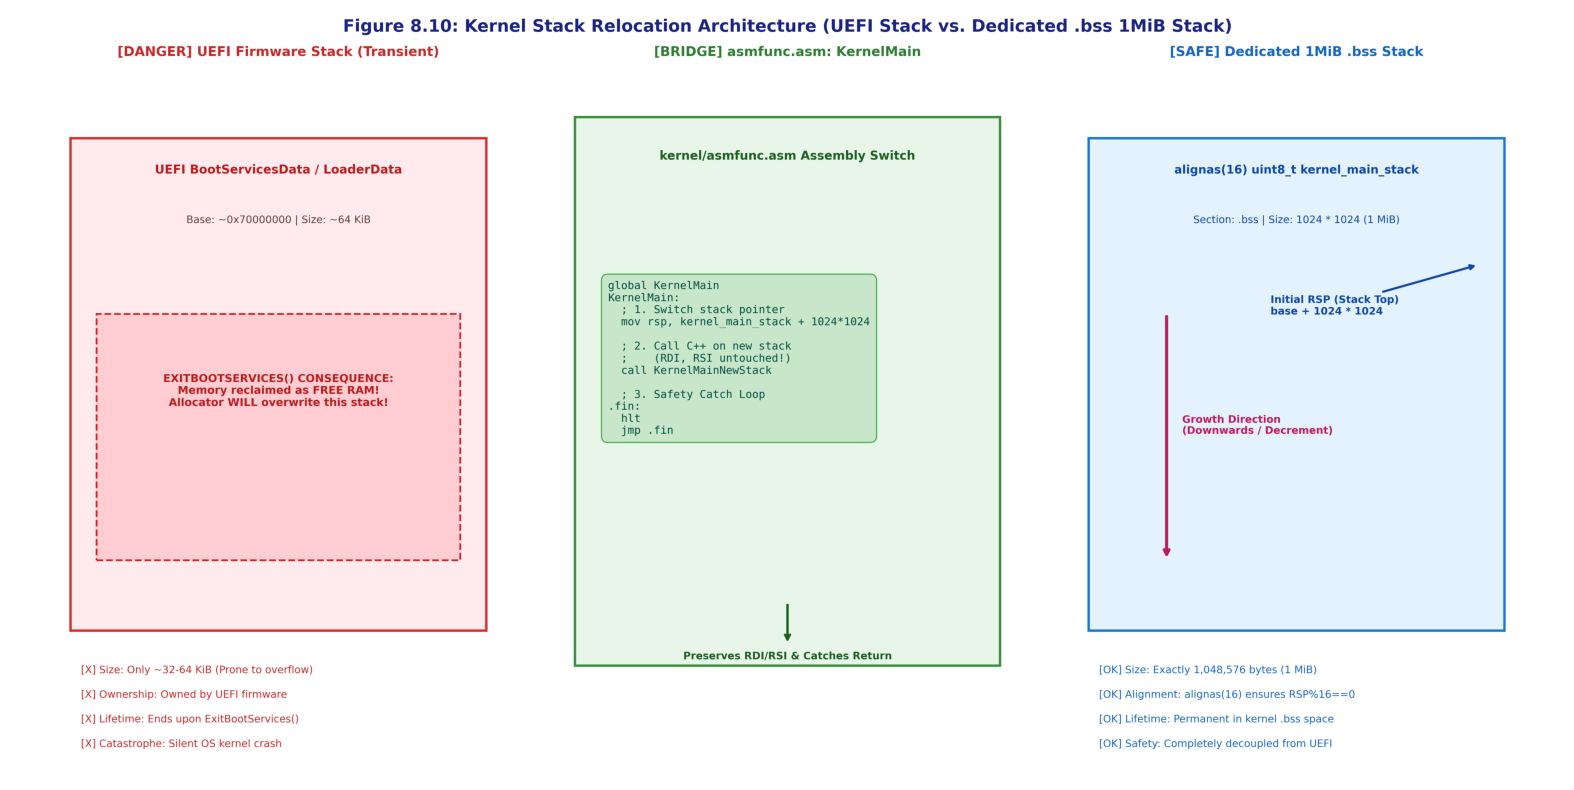

In [5]:
# Figure 8.10 の表示
img_path10 = os.path.join(repo_root, "8", "result", "fig8_10_kernel_stack_relocation_architecture.png")
img10 = Image.open(img_path10)
fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(img10)
ax.axis("off")
plt.tight_layout()
plt.show()


### 図版 8.11: System V AMD64 ABI 16 バイトアライメントとスタックフレーム遷移

関数呼び出しの各段階における $\text{RSP} \pmod{16}$ の遷移と、128 ビット SSE 命令（`movaps`）がアライメント違反時に一般保護例外（`#GP`）を引き起こすハードウェアメカニズムを解説します。


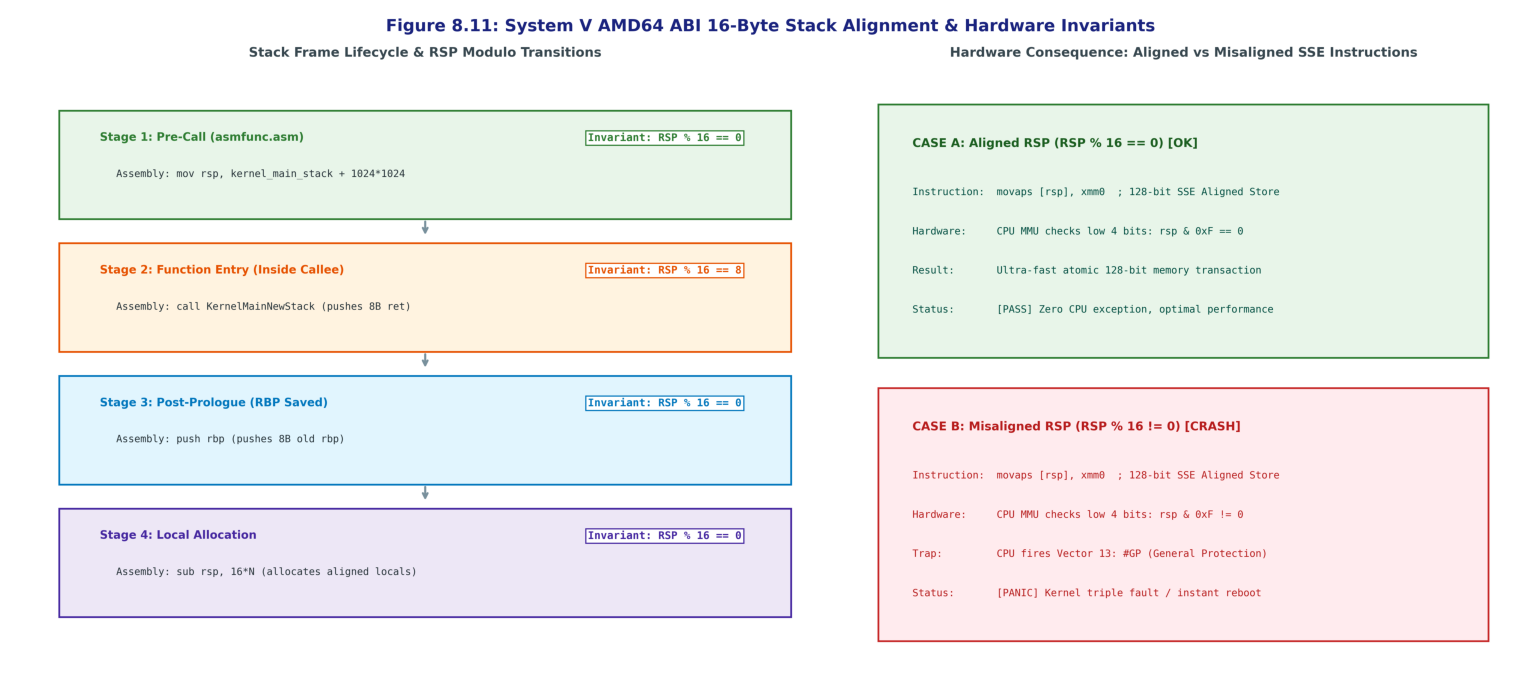

In [6]:
# Figure 8.11 の表示
img_path11 = os.path.join(repo_root, "8", "result", "fig8_11_system_v_abi_stack_alignment_rules.png")
img11 = Image.open(img_path11)
fig, ax = plt.subplots(figsize=(16, 7))
ax.imshow(img11)
ax.axis("off")
plt.tight_layout()
plt.show()


### 図版 8.12: Full Descending Stack のポインタ演算と 1MiB スタック容量

x86-64 の下位伸長スタックにおける初期アドレス計算式、`push`/`pop` に伴うポインタ移動、および UEFI スタック比 16 倍に拡大されたスタックフレーム許容量（16,384 フレーム）を視覚化します。


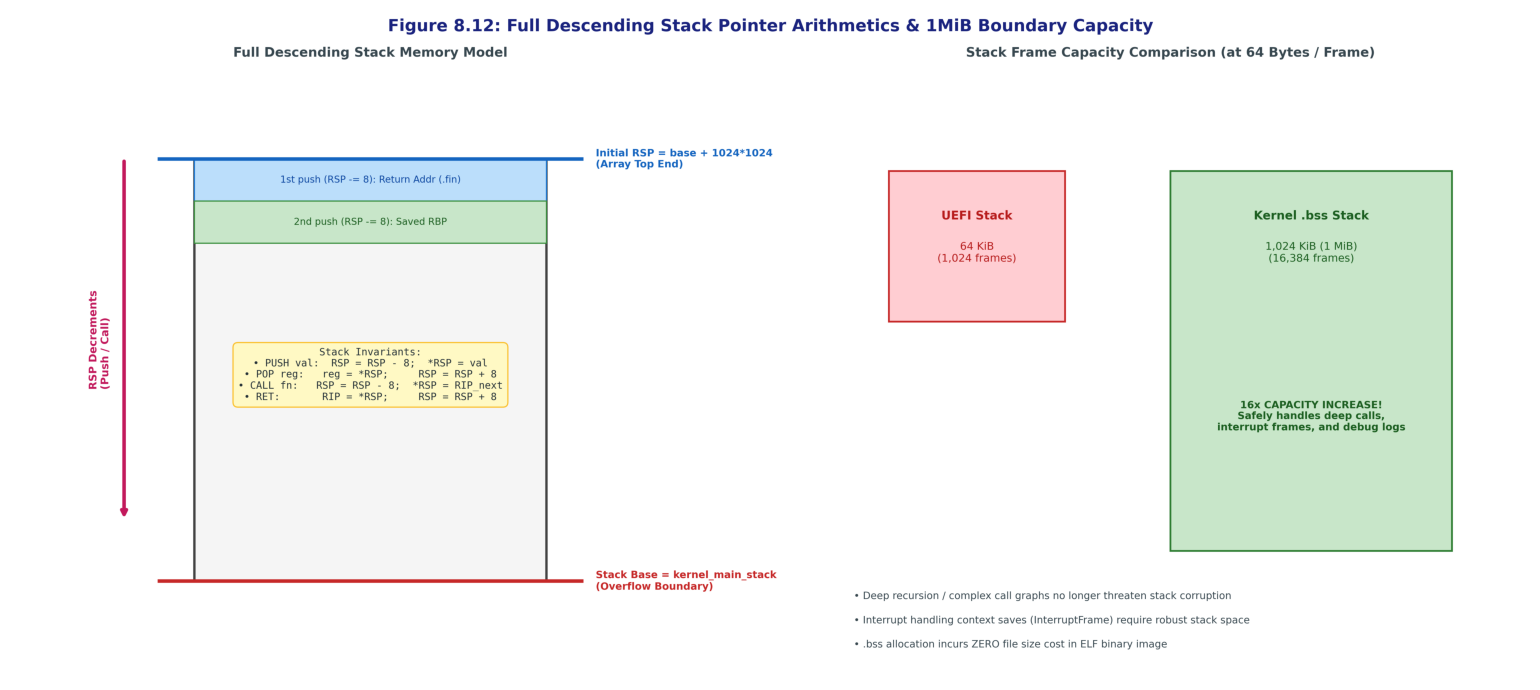

In [7]:
# Figure 8.12 の表示
img_path12 = os.path.join(repo_root, "8", "result", "fig8_12_stack_growth_and_pointer_arithmetics.png")
img12 = Image.open(img_path12)
fig, ax = plt.subplots(figsize=(16, 7))
ax.imshow(img12)
ax.axis("off")
plt.tight_layout()
plt.show()


---

## 8.4.7 本節のまとめと次節（8.5 セグメンテーションの設定）への展望

### 1. 本節で達成した設計の成果

1. **UEFI スタックからの完全脱却**:
   - `ExitBootServices()` 呼び出し後に空きメモリとして回収・再利用されてしまう UEFI ファームウェアスタックを放棄し、カーネルの永続的な `.bss` 領域に 1 MiB の専用スタックを確立しました。
2. **System V AMD64 ABI 規約の完全準拠**:
   - `alignas(16)` と $1024 \times 1024$ バイトのサイズ設定により、Pre-Call での $\text{RSP} \equiv 0 \pmod{16}$、Function Entry での $\text{RSP} \equiv 8 \pmod{16}$ を数学的に保証し、SSE/AVX 命令のクラッシュ（`#GP`）を根絶しました。
3. **アセンブリと C++ のシームレスな結合**:
   - `asmfunc.asm` の `KernelMain` により、引数レジスタ `RDI`, `RSI` を一切汚染することなく `KernelMainNewStack` へフォワードし、安全弁としての `.fin: hlt` ループを構築しました。

---

### 2. 次節への展望：8.5 セグメンテーションの設定 (`8/8.5_Setting_Up_GDT_Segmentation.ipynb`)

スタック領域の安全性を確保したカーネルですが、まだ CPU のメモリハードウェア設定は **「UEFI ファームウェアが設定した仮の状態」** のままです。

特に：
- **GDT (Global Descriptor Table)**: セグメントセレクタ（コードセグメント `CS`、データセグメント `SS`）の設定。
- **ページングテーブル**: 仮想アドレスと物理アドレスの対応関係。

次節（8.5節）では、x86-64 CPU におけるセグメンテーションの役割を解き明かし、カーネル自身の手で GDT を構築して `LGDT` 命令で CPU にロードする手順を導出します！
